# HAM10000 Skin Lesion Classification

##  Model Evaluation and Performance Analysis

### Objective
Evaluate the trained Custom CNN and MobileNetV2 models
using the held-out test dataset.

### Evaluation Metrics
- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix
- ROC-AUC

The test dataset will only be used for final evaluation.

In [1]:
# Import libraries for model evaluation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import load_model

# Set visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Define project directories

PROJECT_DIR = Path("..")
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

# Define image configuration
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

# Define class names in the same order used during training
CLASS_NAMES = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
]

NUM_CLASSES = len(CLASS_NAMES)

print("Configuration completed!")
print("Number of classes:", NUM_CLASSES)

Configuration completed!
Number of classes: 7


In [3]:
# Load the held-out test metadata

test_df = pd.read_csv(OUTPUT_DIR / "test.csv")

print("Test dataset shape:", test_df.shape)

test_df.head()

Test dataset shape: (2014, 10)


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,label,split
0,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0026769.jpg,2,Testing
1,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0025661.jpg,2,Testing
2,HAM_0001396,ISIC_0025276,bkl,histo,55.0,female,trunk,..\data\HAM10000_images_part_1\ISIC_0025276.jpg,2,Testing
3,HAM_0007207,ISIC_0031326,bkl,histo,65.0,male,back,..\data\HAM10000_images_part_2\ISIC_0031326.jpg,2,Testing
4,HAM_0001773,ISIC_0024832,bkl,histo,40.0,female,face,..\data\HAM10000_images_part_1\ISIC_0024832.jpg,2,Testing


In [4]:
# Custom CNN expects pixel values scaled between 0 and 1

custom_test_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

custom_test_generator = custom_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

print("Custom CNN test generator created!")

Found 2014 validated image filenames belonging to 7 classes.
Custom CNN test generator created!


In [5]:
# MobileNetV2 requires its own preprocessing function

from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

mobilenet_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

mobilenet_test_generator = mobilenet_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

print("MobileNetV2 test generator created!")

Found 2014 validated image filenames belonging to 7 classes.
MobileNetV2 test generator created!


In [6]:
# Load the trained Custom CNN model

custom_model_path = MODEL_DIR / "skin_lesion_custom_cnn.keras"

custom_model = load_model(custom_model_path)

print("Custom CNN model loaded successfully!")

Custom CNN model loaded successfully!


In [8]:
# Load the trained MobileNetV2 model

mobilenet_model_path = MODEL_DIR / "mobilenetv2_finetuned_best.keras"

mobilenet_model = load_model(mobilenet_model_path)

print("MobileNetV2 model loaded successfully!")

MobileNetV2 model loaded successfully!


In [9]:
# Evaluate Custom CNN on the held-out test data

custom_loss, custom_accuracy, custom_precision, custom_recall = (
    custom_model.evaluate(
        custom_test_generator,
        verbose=1
    )
)

print("Custom CNN Test Results")
print("-----------------------")
print("Test Loss:", round(custom_loss, 4))
print("Test Accuracy:", round(custom_accuracy, 4))
print("Test Precision:", round(custom_precision, 4))
print("Test Recall:", round(custom_recall, 4))

63/63 ━━━━━━━━━━━━━━━━━━━━ 40s 627ms/step - accuracy: 0.7403 - loss: 0.6905 - precision: 0.8638 - recall: 0.6266
Custom CNN Test Results
-----------------------
Test Loss: 0.6905
Test Accuracy: 0.7403
Test Precision: 0.8638
Test Recall: 0.6266


In [10]:
# Reset generator to ensure predictions start from the first batch

custom_test_generator.reset()

# Generate class probabilities
custom_probabilities = custom_model.predict(
    custom_test_generator,
    verbose=1
)

# Convert probabilities into predicted class indices
custom_predictions = np.argmax(
    custom_probabilities,
    axis=1
)

# Get true class indices
y_true = custom_test_generator.classes

print("Prediction shape:", custom_probabilities.shape)
print("Predicted labels:", custom_predictions[:10])
print("Actual labels:", y_true[:10])

63/63 ━━━━━━━━━━━━━━━━━━━━ 23s 365ms/step
Prediction shape: (2014, 7)
Predicted labels: [0 0 5 1 5 5 5 5 2 2]
Actual labels: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


In [11]:
# Generate detailed classification report

custom_report = classification_report(
    y_true,
    custom_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    zero_division=0
)

print(custom_report)

              precision    recall  f1-score   support

       akiec       0.34      0.35      0.35        68
         bcc       0.35      0.54      0.42       100
         bkl       0.52      0.33      0.40       205
          df       0.00      0.00      0.00        22
         mel       0.51      0.33      0.40       222
          nv       0.84      0.92      0.88      1363
        vasc       0.64      0.41      0.50        34

    accuracy                           0.74      2014
   macro avg       0.46      0.41      0.42      2014
weighted avg       0.72      0.74      0.72      2014



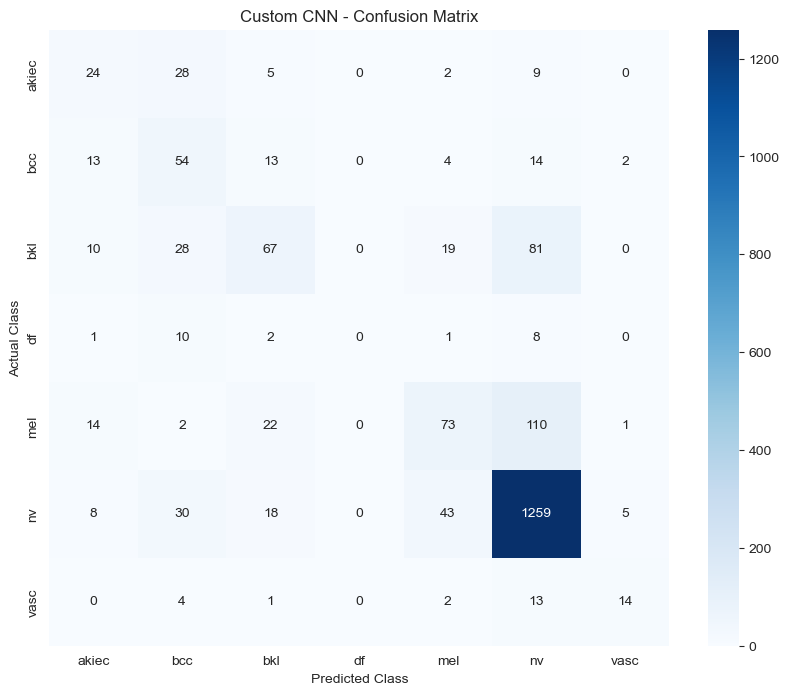

In [12]:
# Calculate confusion matrix

custom_cm = confusion_matrix(
    y_true,
    custom_predictions,
    labels=np.arange(NUM_CLASSES)
)

# Visualize confusion matrix

plt.figure(figsize=(10, 8))

sns.heatmap(
    custom_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("Custom CNN - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [13]:
# Evaluate MobileNetV2 on the held-out test data

mobilenet_loss, mobilenet_accuracy = mobilenet_model.evaluate(
    mobilenet_test_generator,
    verbose=1
)

print("MobileNetV2 Test Results")
print("------------------------")
print("Test Loss:", round(mobilenet_loss, 4))
print("Test Accuracy:", round(mobilenet_accuracy, 4))

63/63 ━━━━━━━━━━━━━━━━━━━━ 37s 551ms/step - accuracy: 0.7627 - loss: 0.6726
MobileNetV2 Test Results
------------------------
Test Loss: 0.6726
Test Accuracy: 0.7627


In [14]:
# Reset the generator before prediction

mobilenet_test_generator.reset()

# Generate class probabilities
mobilenet_probabilities = mobilenet_model.predict(
    mobilenet_test_generator,
    verbose=1
)

# Convert probabilities into class indices
mobilenet_predictions = np.argmax(
    mobilenet_probabilities,
    axis=1
)

# Obtain actual labels
y_true_mobilenet = mobilenet_test_generator.classes

print("Prediction shape:", mobilenet_probabilities.shape)
print("Predicted labels:", mobilenet_predictions[:10])

63/63 ━━━━━━━━━━━━━━━━━━━━ 37s 575ms/step
Prediction shape: (2014, 7)
Predicted labels: [2 4 2 2 5 1 5 5 2 0]


In [15]:
# Generate MobileNetV2 classification report

mobilenet_report = classification_report(
    y_true_mobilenet,
    mobilenet_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    zero_division=0
)

print(mobilenet_report)

              precision    recall  f1-score   support

       akiec       0.57      0.19      0.29        68
         bcc       0.56      0.49      0.52       100
         bkl       0.46      0.52      0.49       205
          df       0.00      0.00      0.00        22
         mel       0.44      0.45      0.44       222
          nv       0.88      0.91      0.90      1363
        vasc       0.74      0.74      0.74        34

    accuracy                           0.76      2014
   macro avg       0.52      0.47      0.48      2014
weighted avg       0.75      0.76      0.75      2014



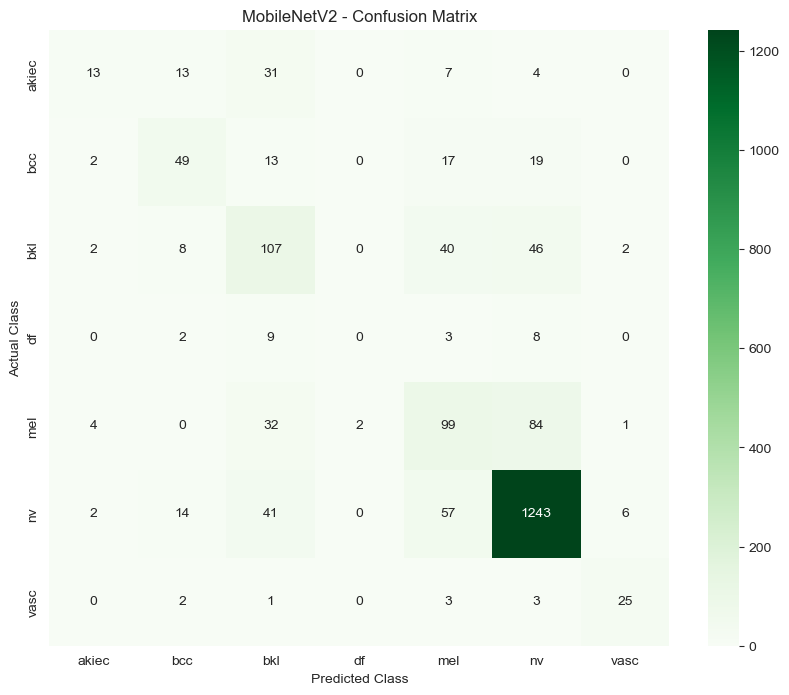

In [16]:
# Calculate confusion matrix

mobilenet_cm = confusion_matrix(
    y_true_mobilenet,
    mobilenet_predictions,
    labels=np.arange(NUM_CLASSES)
)

# Visualize confusion matrix

plt.figure(figsize=(10, 8))

sns.heatmap(
    mobilenet_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [17]:
# Calculate macro-averaged evaluation metrics for both models

# Custom CNN metrics
custom_metrics = {
    "Model": "Custom CNN",
    "Accuracy": accuracy_score(y_true, custom_predictions),
    "Precision": precision_score(
        y_true, custom_predictions,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_true, custom_predictions,
        average="macro", zero_division=0
    ),
    "F1-Score": f1_score(
        y_true, custom_predictions,
        average="macro", zero_division=0
    )
}

# MobileNetV2 metrics
mobilenet_metrics = {
    "Model": "MobileNetV2",
    "Accuracy": accuracy_score(
        y_true_mobilenet, mobilenet_predictions
    ),
    "Precision": precision_score(
        y_true_mobilenet, mobilenet_predictions,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_true_mobilenet, mobilenet_predictions,
        average="macro", zero_division=0
    ),
    "F1-Score": f1_score(
        y_true_mobilenet, mobilenet_predictions,
        average="macro", zero_division=0
    )
}

print("Evaluation metrics calculated successfully!")

Evaluation metrics calculated successfully!


In [18]:
# Create a DataFrame to compare both models

comparison_df = pd.DataFrame([
    custom_metrics,
    mobilenet_metrics
])

comparison_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Custom CNN,0.740318,0.456923,0.412009,0.421765
1,MobileNetV2,0.762661,0.519441,0.470904,0.481313


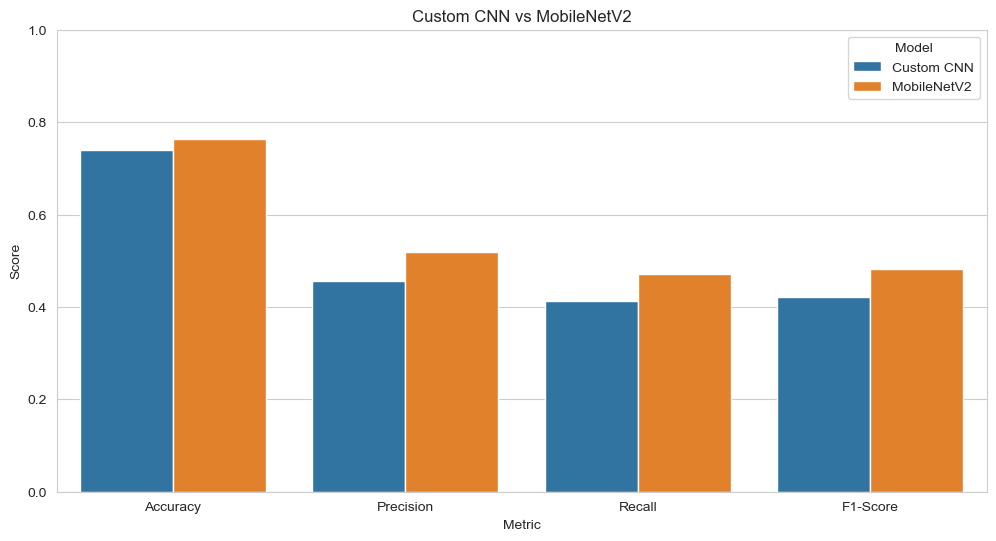

In [19]:
# Convert metrics into a format suitable for plotting

comparison_melted = comparison_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

# Plot model comparison

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_melted,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Custom CNN vs MobileNetV2")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Model")

plt.show()

## ROC-AUC Analysis

ROC-AUC measures how well a classification model
distinguishes between different classes.

For this seven-class classification problem,
we use the One-vs-Rest (OvR) approach.

Macro ROC-AUC calculates the average AUC across classes.

In [20]:
# Calculate macro One-vs-Rest ROC-AUC

try:
    custom_auc = roc_auc_score(
        y_true,
        custom_probabilities,
        labels=np.arange(NUM_CLASSES),
        multi_class="ovr",
        average="macro"
    )

    mobilenet_auc = roc_auc_score(
        y_true_mobilenet,
        mobilenet_probabilities,
        labels=np.arange(NUM_CLASSES),
        multi_class="ovr",
        average="macro"
    )

    print("Custom CNN Macro ROC-AUC:", round(custom_auc, 4))
    print("MobileNetV2 Macro ROC-AUC:", round(mobilenet_auc, 4))

except ValueError as error:
    print("ROC-AUC could not be calculated:", error)
    print("Check whether every class is represented in the test set.")

Custom CNN Macro ROC-AUC: 0.9041
MobileNetV2 Macro ROC-AUC: 0.9222


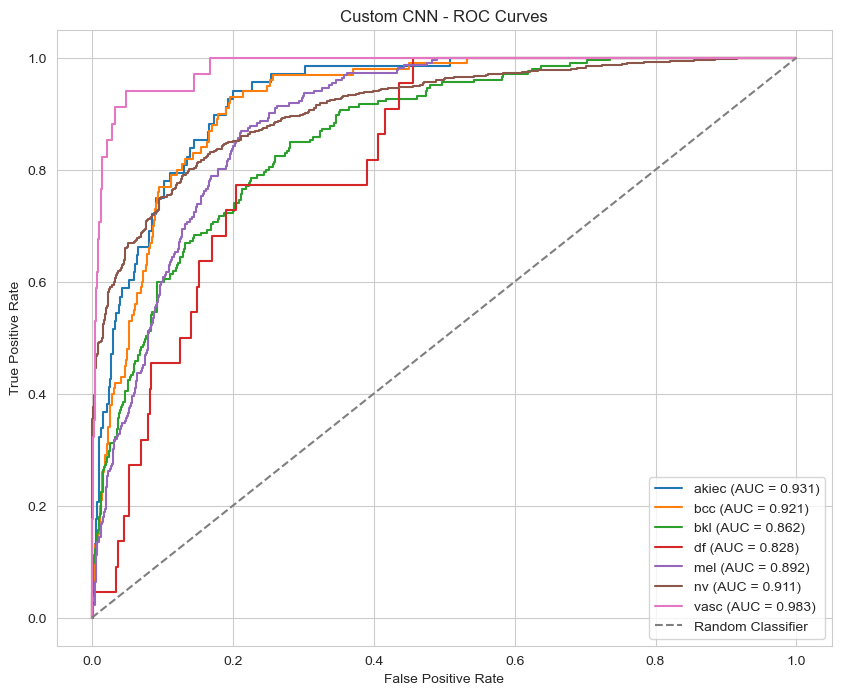

In [21]:
# Convert true labels into one-hot encoded format

y_true_binary = label_binarize(
    y_true,
    classes=np.arange(NUM_CLASSES)
)

# Plot one ROC curve for each class

plt.figure(figsize=(10, 8))

for class_index, class_name in enumerate(CLASS_NAMES):

    # Skip a class if the test data has no positive or negative samples
    if len(np.unique(y_true_binary[:, class_index])) < 2:
        continue

    fpr, tpr, thresholds = roc_curve(
        y_true_binary[:, class_index],
        custom_probabilities[:, class_index]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {class_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("Custom CNN - ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.show()

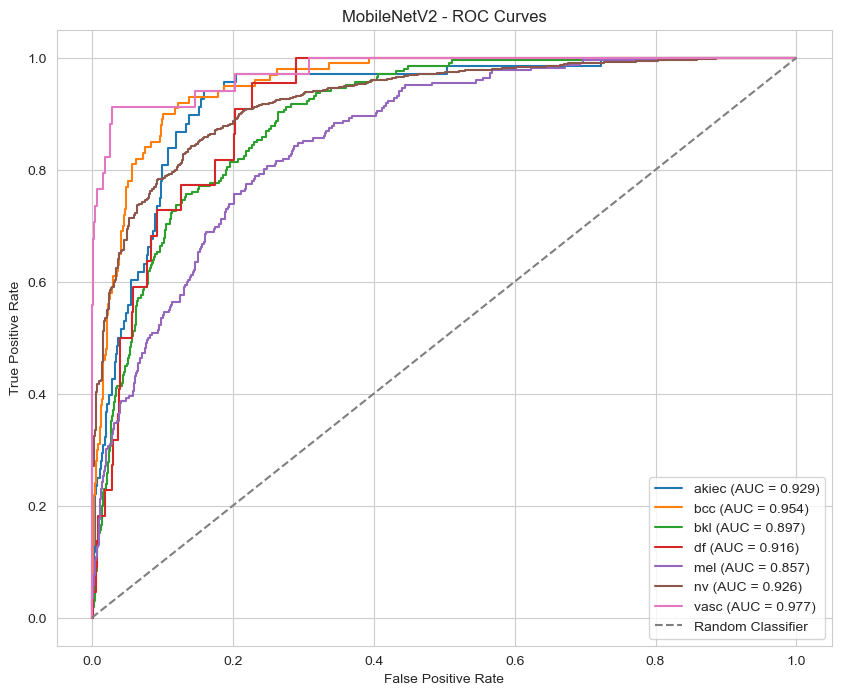

In [22]:
# Plot one ROC curve for each MobileNetV2 class

plt.figure(figsize=(10, 8))

for class_index, class_name in enumerate(CLASS_NAMES):

    if len(np.unique(y_true_binary[:, class_index])) < 2:
        continue

    fpr, tpr, thresholds = roc_curve(
        y_true_binary[:, class_index],
        mobilenet_probabilities[:, class_index]
    )

    class_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"{class_name} (AUC = {class_auc:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("MobileNetV2 - ROC Curves")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)

plt.show()

In [23]:
# Generate class-wise performance for Custom CNN

custom_report_dict = classification_report(
    y_true,
    custom_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

custom_class_report = pd.DataFrame(
    custom_report_dict
).transpose()

custom_class_report

,precision,recall,f1-score,support
akiec,0.342857,0.352941,0.347826,68.000000
bcc,0.346154,0.540000,0.421875,100.000000
bkl,0.523438,0.326829,0.402402,205.000000
df,0.000000,0.000000,0.000000,22.000000
mel,0.506944,0.328829,0.398907,222.000000
nv,0.842704,0.923698,0.881344,1363.000000
vasc,0.636364,0.411765,0.500000,34.000000
accuracy,0.740318,0.740318,0.740318,0.740318
macro avg,0.456923,0.412009,0.421765,2014.000000
weighted avg,0.718976,0.740318,0.722523,2014.000000


In [24]:
# Generate class-wise performance for MobileNetV2

mobilenet_report_dict = classification_report(
    y_true_mobilenet,
    mobilenet_predictions,
    labels=np.arange(NUM_CLASSES),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

mobilenet_class_report = pd.DataFrame(
    mobilenet_report_dict
).transpose()

mobilenet_class_report

,precision,recall,f1-score,support
akiec,0.565217,0.191176,0.285714,68.000000
bcc,0.556818,0.490000,0.521277,100.000000
bkl,0.457265,0.521951,0.487472,205.000000
df,0.000000,0.000000,0.000000,22.000000
mel,0.438053,0.445946,0.441964,222.000000
nv,0.883440,0.911959,0.897473,1363.000000
vasc,0.735294,0.735294,0.735294,34.000000
accuracy,0.762661,0.762661,0.762661,0.762661
macro avg,0.519441,0.470904,0.481313,2014.000000
weighted avg,0.751853,0.762661,0.753654,2014.000000


In [25]:
# Identify images where Custom CNN predictions are incorrect

custom_errors = test_df.copy()

custom_errors["actual_class"] = [
    CLASS_NAMES[index] for index in y_true
]

custom_errors["predicted_class"] = [
    CLASS_NAMES[index] for index in custom_predictions
]

custom_errors["correct"] = (
    custom_errors["actual_class"] ==
    custom_errors["predicted_class"]
)

# Display incorrectly classified images
custom_errors = custom_errors[
    custom_errors["correct"] == False
].copy()

print("Total misclassified images:", len(custom_errors))

custom_errors.head(10)

Total misclassified images: 523


,lesion_id,image_id,dx,dx_type,age,sex,localization,image_path,label,split,actual_class,predicted_class,correct
0,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0026769.jpg,2,Testing,bkl,akiec,False
1,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,..\data\HAM10000_images_part_1\ISIC_0025661.jpg,2,Testing,bkl,akiec,False
2,HAM_0001396,ISIC_0025276,bkl,histo,55.0,female,trunk,..\data\HAM10000_images_part_1\ISIC_0025276.jpg,2,Testing,bkl,nv,False
3,HAM_0007207,ISIC_0031326,bkl,histo,65.0,male,back,..\data\HAM10000_images_part_2\ISIC_0031326.jpg,2,Testing,bkl,bcc,False
4,HAM_0001773,ISIC_0024832,bkl,histo,40.0,female,face,..\data\HAM10000_images_part_1\ISIC_0024832.jpg,2,Testing,bkl,nv,False
5,HAM_0001773,ISIC_0026958,bkl,histo,40.0,female,face,..\data\HAM10000_images_part_1\ISIC_0026958.jpg,2,Testing,bkl,nv,False
6,HAM_0002127,ISIC_0030768,bkl,histo,40.0,male,face,..\data\HAM10000_images_part_2\ISIC_0030768.jpg,2,Testing,bkl,nv,False
7,HAM_0002127,ISIC_0029837,bkl,histo,40.0,male,face,..\data\HAM10000_images_part_2\ISIC_0029837.jpg,2,Testing,bkl,nv,False
10,HAM_0002957,ISIC_0026153,bkl,histo,70.0,male,back,..\data\HAM10000_images_part_1\ISIC_0026153.jpg,2,Testing,bkl,nv,False
11,HAM_0002957,ISIC_0025876,bkl,histo,70.0,male,back,..\data\HAM10000_images_part_1\ISIC_0025876.jpg,2,Testing,bkl,nv,False


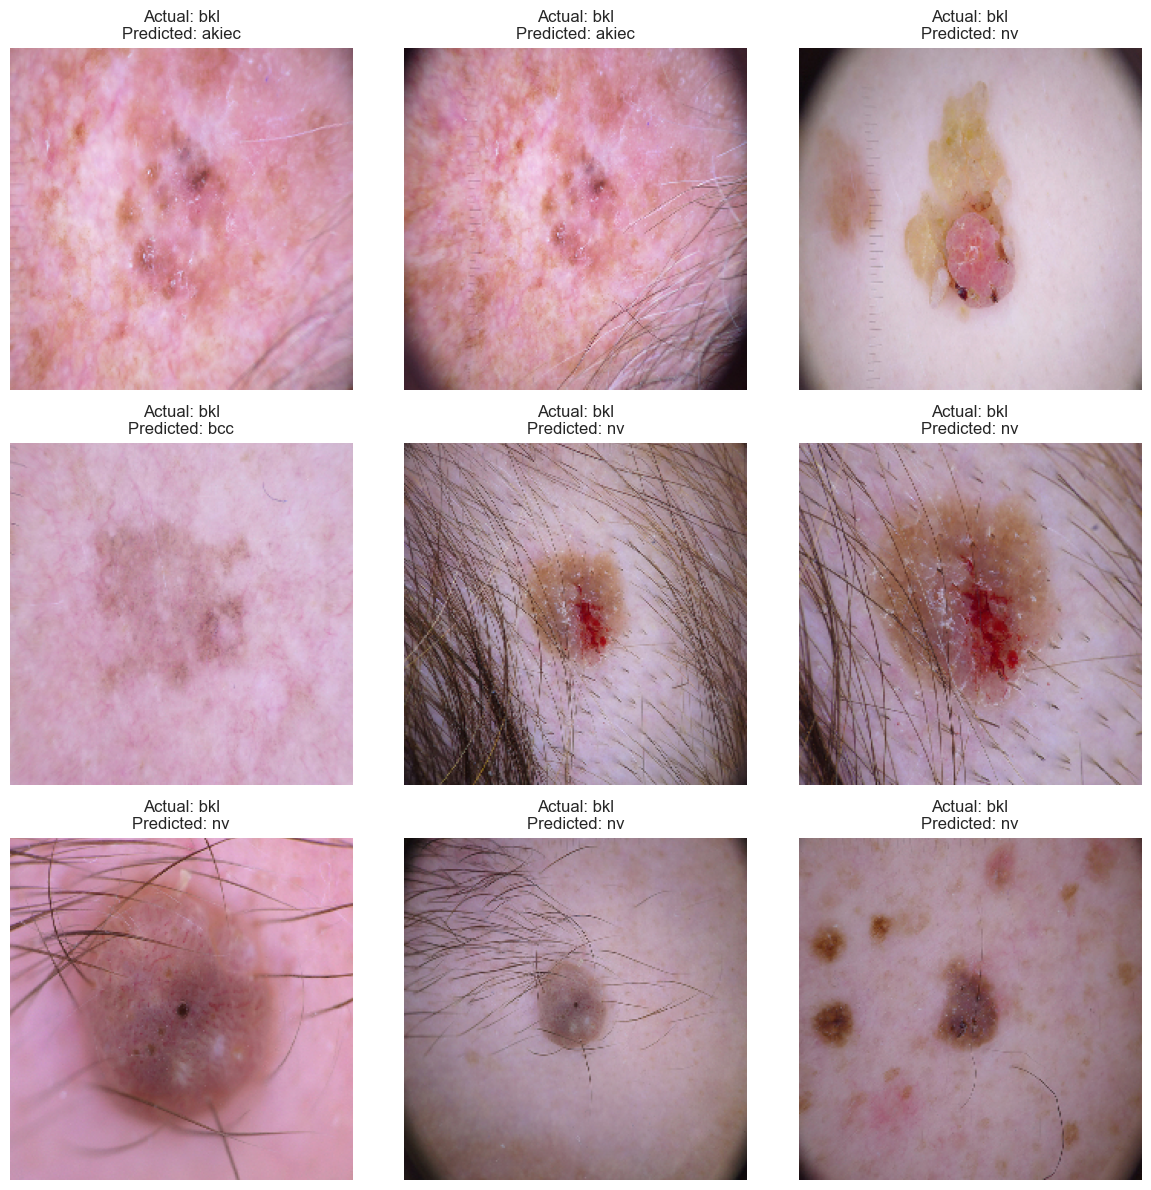

In [26]:
# Display a sample of misclassified images

sample_errors = custom_errors.head(9)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, (_, row) in zip(axes.flatten(), sample_errors.iterrows()):

    # Load the image
    image = tf.keras.utils.load_img(
        row["image_path"],
        target_size=IMAGE_SIZE
    )

    # Display the image
    ax.imshow(image)

    # Display actual and predicted labels
    ax.set_title(
        f"Actual: {row['actual_class']}\n"
        f"Predicted: {row['predicted_class']}"
    )

    ax.axis("off")

# Hide unused axes
for ax in axes.flatten()[len(sample_errors):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [27]:
# Save model comparison metrics

comparison_df.to_csv(
    OUTPUT_DIR / "model_comparison.csv",
    index=False
)

# Save Custom CNN classification report
custom_class_report.to_csv(
    OUTPUT_DIR / "custom_cnn_classification_report.csv"
)

# Save MobileNetV2 classification report
mobilenet_class_report.to_csv(
    OUTPUT_DIR / "mobilenetv2_classification_report.csv"
)

# Save confusion matrices
pd.DataFrame(
    custom_cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    OUTPUT_DIR / "custom_cnn_confusion_matrix.csv"
)

pd.DataFrame(
    mobilenet_cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    OUTPUT_DIR / "mobilenetv2_confusion_matrix.csv"
)

# Save misclassified image details
custom_errors.to_csv(
    OUTPUT_DIR / "custom_cnn_misclassified_images.csv",
    index=False
)

print("All evaluation results saved successfully!")

All evaluation results saved successfully!


In [28]:
# Display final model comparison

print("=" * 55)
print("HAM10000 MODEL EVALUATION SUMMARY")
print("=" * 55)

for _, row in comparison_df.iterrows():

    print("\nModel:", row["Model"])
    print("Accuracy:", round(row["Accuracy"], 4))
    print("Macro Precision:", round(row["Precision"], 4))
    print("Macro Recall:", round(row["Recall"], 4))
    print("Macro F1-score:", round(row["F1-Score"], 4))

print("\nEvaluation completed successfully!")

HAM10000 MODEL EVALUATION SUMMARY

Model: Custom CNN
Accuracy: 0.7403
Macro Precision: 0.4569
Macro Recall: 0.412
Macro F1-score: 0.4218

Model: MobileNetV2
Accuracy: 0.7627
Macro Precision: 0.5194
Macro Recall: 0.4709
Macro F1-score: 0.4813

Evaluation completed successfully!


## Conclusion

The Custom CNN and MobileNetV2 models were evaluated
using the held-out HAM10000 test dataset.

The following evaluation methods were used:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-score
- Confusion Matrix
- ROC-AUC
- Class-wise Classification Report
- Misclassification Analysis

The evaluation results were saved in the outputs folder.

### Important
Model performance should be interpreted using
class-wise metrics, especially because HAM10000
contains an imbalanced class distribution.

The held-out test set is reserved for final reporting.
Model selection and hyperparameter tuning should
primarily use validation results.

